In [6]:
%pip install scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [7]:
import pandas as pd
import numpy as np

from sklearn.metrics import mean_absolute_error, mean_squared_error

df = pd.read_csv("../data/processed/sales_features.csv")

df["date"] = pd.to_datetime(df["date"])

df = df.sort_values(
    ["date", "store", "item"]
).reset_index(drop=True)

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (899000, 17)
        date  store  item  sales  year  month  day  day_of_week  week_of_year  \
0 2013-01-29      1     1      6  2013      1   29            1             5   
1 2013-01-29      1     2     35  2013      1   29            1             5   
2 2013-01-29      1     3     15  2013      1   29            1             5   
3 2013-01-29      1     4     13  2013      1   29            1             5   
4 2013-01-29      1     5      9  2013      1   29            1             5   

   quarter  is_weekend  lag_1  lag_7  lag_14  lag_28  rolling_mean_7  \
0        1           0   11.0    7.0     5.0    13.0       10.428571   
1        1           0   16.0   29.0    27.0    33.0       27.571429   
2        1           0   14.0   20.0    12.0    15.0       17.571429   
3        1           0    7.0   11.0    14.0    10.0        9.000000   
4        1           0    9.0    9.0    10.0    11.0        9.428571   

   rolling_mean_28  
0        10.714286  
1        2

In [8]:
# Split the dataset chronologically
train = df[df["date"] <= "2016-12-31"].copy()

validation = df[
    (df["date"] >= "2017-01-01") &
    (df["date"] <= "2017-06-30")
].copy()

test = df[
    (df["date"] >= "2017-07-01") &
    (df["date"] <= "2017-12-31")
].copy()

print("Training shape:", train.shape)
print("Validation shape:", validation.shape)
print("Testing shape:", test.shape)

Training shape: (716500, 17)
Validation shape: (90500, 17)
Testing shape: (92000, 17)


In [9]:
# verify train , test and validation dataset
print("Training:", train["date"].min(), "to", train["date"].max())

print("Validation:", validation["date"].min(), "to", validation["date"].max())

print("Testing:", test["date"].min(), "to", test["date"].max())

Training: 2013-01-29 00:00:00 to 2016-12-31 00:00:00
Validation: 2017-01-01 00:00:00 to 2017-06-30 00:00:00
Testing: 2017-07-01 00:00:00 to 2017-12-31 00:00:00


In [10]:
# Validation predictions
validation["naive_prediction"] = validation["lag_1"]

validation["seasonal_prediction"] = validation["lag_7"]

# Test predictions
test["naive_prediction"] = test["lag_1"]

test["seasonal_prediction"] = test["lag_7"]

In [11]:
# Evaluate forecasting performance
def evaluate_model(actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(mean_squared_error(actual, predicted))

    wape = (
        np.abs(actual - predicted).sum()
        / np.abs(actual).sum()
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE": wape
    }

In [12]:
# Evaluate validation data
validation_results = pd.DataFrame({

    "Naive": evaluate_model(
        validation["sales"],
        validation["naive_prediction"]
    ),

    "Seasonal Naive": evaluate_model(
        validation["sales"],
        validation["seasonal_prediction"]
    )

}).T

print(validation_results)

                      MAE       RMSE       WAPE
Naive           10.894011  14.891796  19.386595
Seasonal Naive   8.462630  11.046334  15.059795


In [13]:
# Evaluate test data
test_results = pd.DataFrame({

    "Naive": evaluate_model(
        test["sales"],
        test["naive_prediction"]
    ),

    "Seasonal Naive": evaluate_model(
        test["sales"],
        test["seasonal_prediction"]
    )

}).T

print(test_results)

                      MAE       RMSE       WAPE
Naive           11.589739  15.863372  18.877715
Seasonal Naive   9.214098  12.113728  15.008199


In [14]:
# Aggregate daily predictions
daily_comparison = test.groupby("date").agg(
    actual_sales=("sales", "sum"),
    naive_sales=("naive_prediction", "sum"),
    seasonal_sales=("seasonal_prediction", "sum")
).reset_index()

daily_comparison.head()

,date,actual_sales,naive_sales,seasonal_sales
0,2017-07-01,42594,37182.0,39501.0
1,2017-07-02,44936,42594.0,42029.0
2,2017-07-03,29775,44936.0,28187.0
3,2017-07-04,34737,29775.0,32849.0
4,2017-07-05,34681,34737.0,32714.0


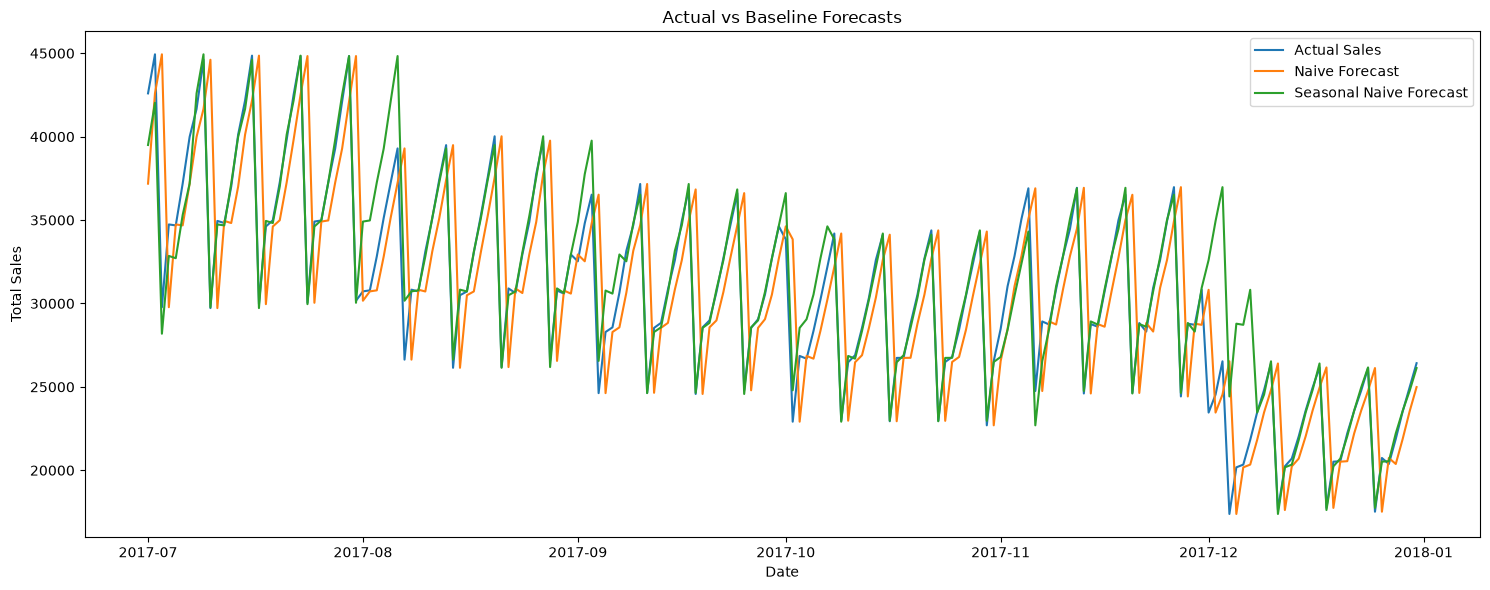

In [15]:
# Plot the comparison
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    daily_comparison["date"],
    daily_comparison["actual_sales"],
    label="Actual Sales"
)

plt.plot(
    daily_comparison["date"],
    daily_comparison["naive_sales"],
    label="Naive Forecast"
)

plt.plot(
    daily_comparison["date"],
    daily_comparison["seasonal_sales"],
    label="Seasonal Naive Forecast"
)

plt.title("Actual vs Baseline Forecasts")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
#  Save baseline results
validation_results.to_csv(
    "../reports/validation_baseline_results.csv"
)

test_results.to_csv(
    "../reports/test_baseline_results.csv"
)

daily_comparison.to_csv(
    "../data/processed/baseline_predictions.csv",
    index=False
)

print("Baseline evaluation completed and saved!")

Baseline evaluation completed and saved!
